# Ray Data: train/test split

train_test_split has two outputs; each one feeds its own count. The builder names the two datasets for you.

**When to use it.** Holding out an evaluation set before training.

The picture below is the graph drawn in Eugo's visual Ray builder, and the cell under *Generated code* is the Ray code the builder produced from it. The code is plain Ray: it runs without the builder.

[Back to the gallery](../README.md) · Tested with Ray 2.55.1

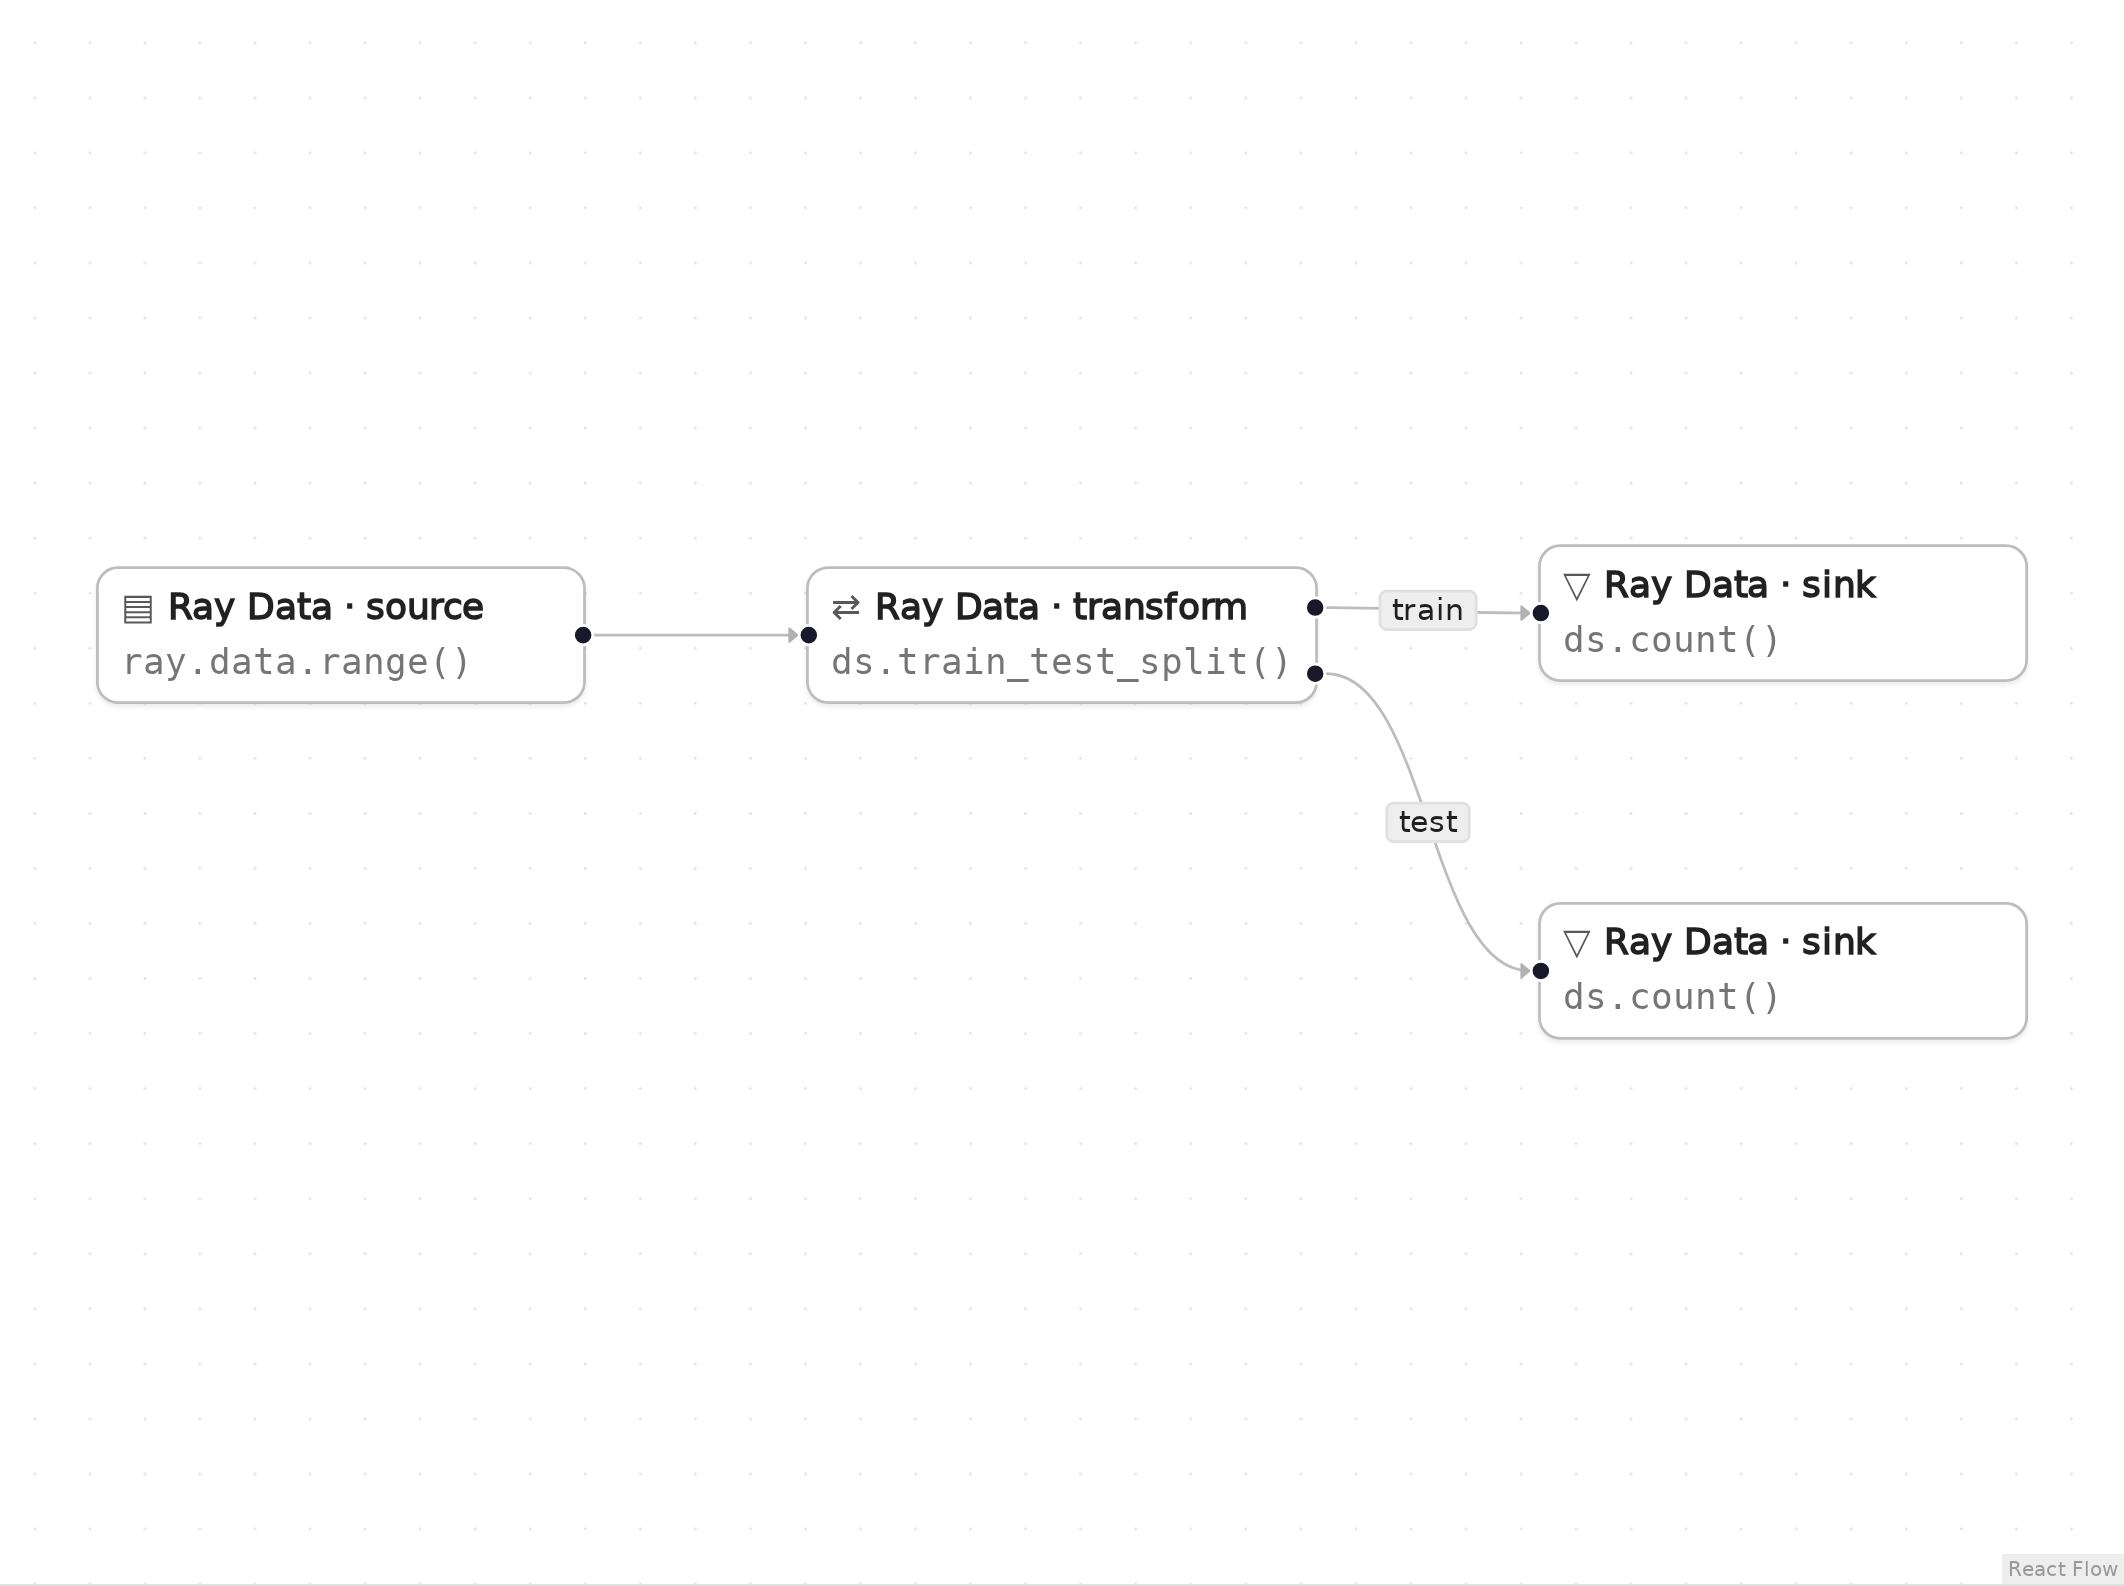

*The graph in Eugo's visual Ray builder.*

## Setup

Start a local Ray instance. The options keep the notebook quiet: no dashboard, and worker logs stay out of the notebook. Ray is capped at four CPUs so the example behaves the same on any machine. The generated code below only calls `ray.init()` when Ray is not running yet, so it reuses this instance.

In [1]:
import ray
ray.init(include_dashboard=False, log_to_driver=False, logging_level="ERROR", num_cpus=4)

RayContext(dashboard_url='', python_version='3.12.3', ray_version='2.55.1', ray_commit='237c2455ebb1ea15a32dd9e1fdeb2d617badc37f')

## User functions

This pattern needs no user functions.

## Generated code

This is the cell the visual builder generated from the graph above.

In [2]:
# Generated with Eugo's visual Ray builder

import ray

if not ray.is_initialized():
    ray.init()

ds_n1 = ray.data.range(100)
ds_n2_0, ds_n2_1 = ds_n1.train_test_split(0.25)
n_train = ds_n2_0.count()
n_test = ds_n2_1.count()

## Check the result

The cell below checks that the generated code did what the graph describes.

In [3]:
assert (n_train, n_test) == (75, 25), (n_train, n_test)
print("train =", n_train, "test =", n_test)

train = 75 test = 25


## How the graph maps to the code

Each step names a node in the picture, the lines of the generated cell it produced, and what those lines do. The node id (for example `n1`) is also the suffix of the variable that holds the node's result.

**Setup** (lines 1, 3 and 5–6)

```python
# Generated with Eugo's visual Ray builder
...
import ray
...
if not ray.is_initialized():
    ray.init()
```

The first line marks the cell as generated. The builder then adds an import for every Ray API the graph uses and a guarded ray.init(), so re-running the cell reuses the running cluster.

**Source** (node `n1`, line 8)

```python
ds_n1 = ray.data.range(100)
```

A 100-row dataset.

**Transform** (node `n2`, line 9)

```python
ds_n2_0, ds_n2_1 = ds_n1.train_test_split(0.25)
```

train_test_split(0.25) returns two datasets; the node has one output handle for each.

**Sink** (node `n3`, line 10)

```python
n_train = ds_n2_0.count()
```

Counts the training split (75 rows).

**Sink** (node `n4`, line 11)

```python
n_test = ds_n2_1.count()
```

Counts the test split (25 rows).

## Clean up

Shut down Ray, so the next notebook starts fresh.

In [4]:
ray.shutdown()